# 제7장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch07


## 7.11 임계값 변화와 혼동행렬·정밀도·재현율

같은 확률 예측을 여러 임계값으로 바꾸어 지표 수식과 혼동행렬을 일대일로 대응한다.

양성은 Wine 원래 클래스 0이다. 임계값을 올리면 양성 예측 집합은 줄어든다. 정밀도는 반드시 단조 증가하지 않는다.

주의: 임계값 선택용 검증 자료다. 최적 F1을 고른 뒤 같은 세트의 점수를 최종 테스트 성능으로 보고하지 않는다.

In [2]:
%run sec_11_threshold_metrics.py

{
  "validation_n": 54,
  "positive_definition": "wine target == 0",
  "at_threshold_0.5": {
    "threshold": 0.49999999999999994,
    "TN": 35,
    "FP": 1,
    "FN": 1,
    "TP": 17,
    "Accuracy": 0.9629629629629629,
    "Precision": 0.9444444444444444,
    "Recall": 0.9444444444444444,
    "F1": 0.9444444444444444
  }
}


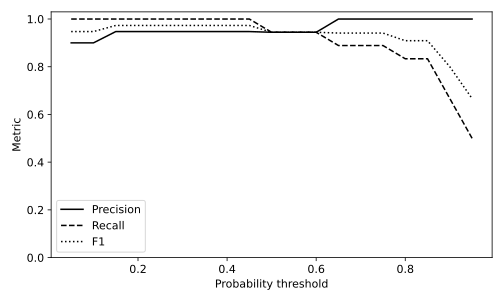

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/threshold_metrics.svg"))

### 확인 과제

CSV에서 임계값 0.5의 TP·FP·FN·TN으로 네 지표를 직접 계산해 JSON과 대조한다.

## 7.12 ROC·PR 곡선과 확률 보정 상태

분류 순위 능력과 확률의 신뢰도를 다른 관점으로 읽는다.

ROC는 FPR/TPR, PR은 Recall/Precision이다. 보정 곡선은 구간 평균 확률과 실제 양성 비율을 비교한다. 비어 있는 구간은 표시되지 않는다.

주의: 작은 테스트 세트와 구간화 결과는 불안정할 수 있다. 보정 곡선 자체가 보정 처리를 수행한 것은 아니다.

In [4]:
%run sec_12_roc_pr.py

{
  "test_n": 54,
  "prevalence": 0.3333333333333333,
  "ROC_AUC": 1.0,
  "AP": 1.0000000000000002,
  "Brier": 0.027331693273780305
}


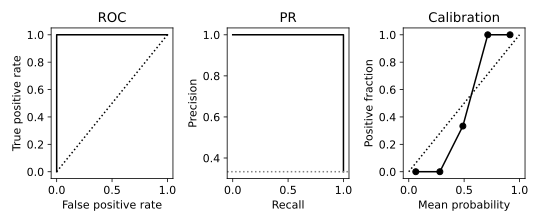

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/roc_pr.svg"))

### 확인 과제

PR 기준선이 양성 비율인 이유를 설명하고, Brier 점수와 AUC 중 어느 지표가 확률 오차를 직접 반영하는지 구분한다.